# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 2</span>


### Exercise 02.1
- Compute the following 1D integral via Monte Carlo 
$$I = \int_0^1 \frac{\pi}{2}\cos(\pi x/2) dx = 1$$

1. sampling a uniform distribution in $[0,1]$
2. using importance sampling (i.e. sampling a non-uniform probability in $[0,1]$)

Show a picture of both your estimations of $I$ and their uncertainties with a large number of *throws* $M$ (e.g. $M\ge 10^4$) as a function of the number of blocks, $N$.

### Exercise 02.2
- 3D Random Walks (RW) on a cubic lattice and in the continuum:</span> Repeat many times (e.g. say $10^4$) the simulation of a random walk in 3D always starting at the origin

1. on a cubic lattice with lattice constant $a=1$; at each discrete time the walker makes a forward or backward step of length equal to $a$ in one of the 3 principal directions of the lattice: $x$, $y$ or $z$
2. in the continuum; at each discrete time the walker makes a step of length equal to $a(=1)$ along a **random direction** obtained by sampling **uniformly** the solid angle: $\theta \in [0,\pi]$ and $\phi \in [0,2\pi]$

Show a picture of $\sqrt{\langle |\vec{r}_N|^2 \rangle_{RW}}$ for both RWs, with their statistical uncertainties, as function of the step $i\in [0,10^2]$.

Suggestion: divide your $M$ throws into a reasonable number of blocks, compute $\sqrt{\langle |\vec{r}_N|^2 \rangle_{RW}}$ as function of the step $i\in [0,10^2]$ in each block and use these values (for fixed $i$) to obtain the average value and its statistical uncertainty.

Note that you could try to fit both results with a function like $f(N)=k\sqrt{N}$. Do your results indicate a diffusive behavior?

# <span style="color:green"> RESULTS: </span>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

In [ ]:
files = [("./OUTPUT/uni_sampling.dat", "Uniform Sampling"), 
         ("./OUTPUT/imp_sampling.dat", "Importance Sampling")]

## Exercise 2.1
The aim of this exercise is to estimate the value of the following integral using two different Monte Carlo techniques:
$$I = \int_0^1 \frac{\pi}{2}\cos\left(\frac{\pi}{2} x\right)\mathrm{d}x = 1$$
Both estimates use the mean method, with this approch the integral is computed as the average of a function evaluated at random points. What changes between the two different estimates is the distribution from which the points are drawn, which can be more or less tailored to the integrand.

### Uniform Sampling
With this method, the integrand $f(x)=\frac{\pi}{2}\cos\left(\frac{\pi}{2}x\right)$ is evaluated at points $x_i$ sampled from a uniform probability density function (PDF) on $[0,1]$. The integral is then approximated by the arithmetic mean of the sampled values:
$$I \approx \frac{1}{N}\sum_{i=1}^N f(x_i), \qquad x_i \sim U(0,1)$$

#### Data collection
To compute the integral, $M=10^5$ points were generated from a uniform distribution and then grouped in $N=100$ blocks of $L=1000$ throws each. The blocks were used to compute the progressive mean and its uncertainty with the data blocking method introduced in notebook 1.

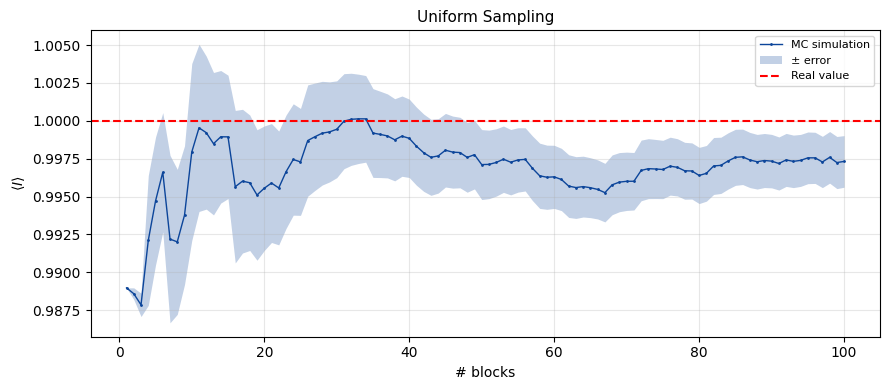

In [3]:
colors = ["#0c459a", "#109e28"]

file, title = files[0]
data = np.loadtxt(file)
n, mean, err = data[:, 0], data[:, 1], data[:, 2]

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(n, mean, color=colors[0], lw=1, marker='o', markersize=1, label='MC simulation')
ax.fill_between(n, mean - err, mean + err, color=colors[0], alpha=0.25, linewidth=0, label='± error')
ax.axhline(y=1.0, color='red', linestyle='--', label='Real value')

ax.set_title(title, fontsize=11)
ax.set_xlabel('# blocks', fontsize=10)
ax.set_ylabel(r'$\langle I \rangle$', fontsize=10)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', fontsize = 8)

plt.tight_layout()
plt.show()

From the graph we can see that the estimate is compatible with the real value within $2\sigma$

### Importance Sampling
This second method instead reduces the variance of the estimate by sampling the points $x_i$ from a non-uniform PDF $d(x)$ that resembles $f(x)$ on $[0,1]$. Applying the mean method to $f/d$, the integral can be computed as:
$$I = \int_0^1 \frac{f(x)}{d(x)}\, d(x)\,\mathrm{d}x \approx \frac{1}{N}\sum_{i=1}^N \frac{f(x_i)}{d(x_i)}, \qquad x_i \sim d(x)$$
The variance is smaller because $d(x)$ has a shape similar to $f(x)$. Points are drawn more often where $f$ is large, and dividing by $d(x)$ compensates for this, so the quantity that is averaged, $f/d$, is much flatter than $f$ itself. Values that are closer to each other give an average that fluctuates less from block to block.

#### Choice and sampling of the PDF $d(x)$
For this integrand, the PDF has been obtained from the first-order Taylor expansion of $f(x)$ around $x=1$, where the function drops to zero. Since $f(1)=0$ and $f'(x)=-\frac{\pi^2}{4}\sin\left(\frac{\pi}{2}x\right)$,
$$f(x) \simeq f'(1)\,(x-1) = \frac{\pi^2}{4}\,(1-x)$$
Only the shape matters as the constant disappears with the normalization, so we take $g(x) = 1 - x$ and, normalizing it on $[0,1]$ with: $C_{norm} = \int_0^1 (1-x)\,\mathrm{d}x = \frac{1}{2}$ , we obtain a valid PDF:
$$d(x) = \frac{g(x)}{C_{norm}} = 2(1 - x)$$
To generate $x$ distributed according to $d(x)$ we used the inversion of the cumulative distribution as it has been done in the previous notebook. Here the cumulative distribution function is:
$$D(x) = \int_0^x 2(1 - t)\,\mathrm{d}t = 2x - x^2$$
Setting $D(x) = y$ with $y \sim U(0,1)$ gives $x^2 - 2x + y = 0$, whose root inside $[0,1]$ is $x = 1 - \sqrt{1 - y}$.

#### Data collection
As for the uniform sampling method, the integral was computed using $M=10^5$ points drawn from the distribution $d(x)=2(1-x)$, grouped in $N=100$ blocks of $L=1000$ throws each, and analyzed with the data blocking method. 

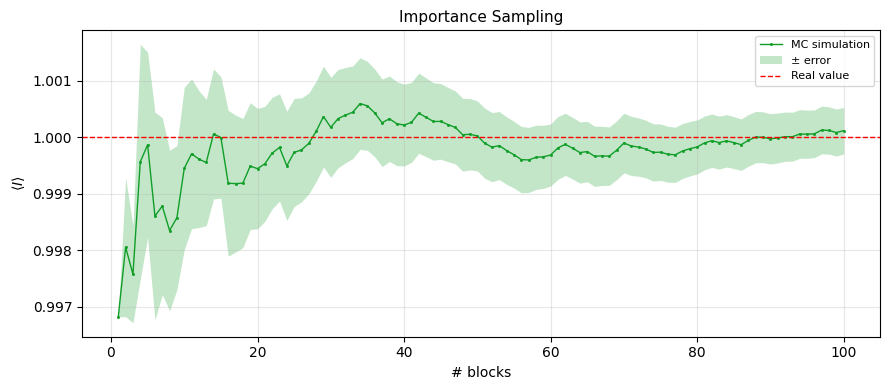

In [4]:
file, title = files[1]
data = np.loadtxt(file)
n, mean, err = data[:, 0], data[:, 1], data[:, 2]

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(n, mean, color=colors[1], lw=1, marker='s', markersize=1, label='MC simulation')
ax.fill_between(n, mean - err, mean + err, color=colors[1], alpha=0.25, linewidth=0, label='± error')
ax.axhline(y=1.0, color='red', linestyle='--', lw =1, label='Real value')

ax.set_title(title, fontsize=11)
ax.set_xlabel('# blocks', fontsize=10)
ax.set_ylabel(r'$\langle I \rangle$', fontsize=10)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', fontsize = 8)

plt.tight_layout()
plt.show()

The plot above demonstrates a significantly better agreement with the exact value of the integral. To directly compare the statistical uncertainties of both methods, we have plotted their progressive averages on the same graph:

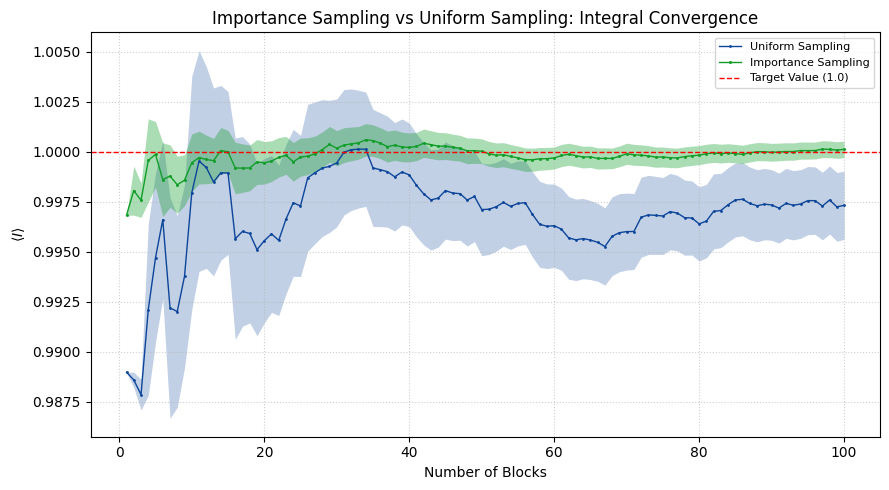

In [5]:
data_uni = np.loadtxt(files[0][0])
data_imp = np.loadtxt(files[1][0])
n_blocks = data_uni[:, 0]

fig, ax = plt.subplots(figsize=(9, 5))

# uniform sampling
ax.plot(n_blocks, data_uni[:, 1], color=colors[0], lw=1, marker='o', markersize=1, label='Uniform Sampling')
ax.fill_between(n_blocks, data_uni[:, 1] - data_uni[:, 2], data_uni[:, 1] + data_uni[:, 2],
                color=colors[0], alpha=0.25, linewidth=0)

# importance sampling
ax.plot(n_blocks, data_imp[:, 1], color=colors[1], lw=1, marker='s', markersize=1, label='Importance Sampling')
ax.fill_between(n_blocks, data_imp[:, 1] - data_imp[:, 2], data_imp[:, 1] + data_imp[:, 2],
                color=colors[1], alpha=0.35, linewidth=0)

ax.axhline(y=1.0, color='red', linestyle='--', linewidth=1, label='Target Value (1.0)')

ax.set_title("Importance Sampling vs Uniform Sampling: Integral Convergence", fontsize=12)
ax.set_xlabel("Number of Blocks", fontsize=10)
ax.set_ylabel(r"$\langle I \rangle$", fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='best', fontsize=8)

plt.tight_layout()
plt.show()

As can be seen, the statistical error associated with importance sampling is significantly smaller, and the estimated value of the integral is substantially more accurate than the result obtained via uniform sampling. This clearly demonstrates the superior efficiency of importance sampling in variance reduction for Monte Carlo integration.

## Exercise 2.2

In this exercise, we simulated a 3D Random Walk (RW) under two different spatial configurations: first on a discrete cubic lattice, then in a continuous 3D space. For both configurations, we evaluated the root mean square (RMS) distance $\sqrt{\langle r^2 \rangle}$ from the origin as a function of the step number $N$, to verify diffusive behavior: specifically, we tested whether the RMS distance follows a square-root law $f(N) = k \sqrt{N}$. This law comes from the fact that the steps are independent, have zero mean and unit length: the cross terms between different steps average to zero, so $\langle|\vec r_N|^2\rangle = N$ hence we expect $\sqrt{\langle|\vec r_N|^2\rangle} = k\sqrt{N}$ with $k=1$.

To evaluate $\sqrt{\langle r^2 \rangle}$ and its statistical uncertainty, we first computed the block averages and errors of the mean square distance $\langle r^2 \rangle$ using the data blocking method. We then took the square root of the mean value and propagated the uncertainty with first-order error propagation:

$$\sigma_{\sqrt{\langle r^2 \rangle}} = \frac{\sigma_{\langle r^2 \rangle}}{2 \sqrt{\langle r^2 \rangle}}$$

Computing $\langle r^2 \rangle$ via data blocking before applying the non-linear square-root function is preferred to taking the square root of each individual trajectory prior to averaging. Since the square root is concave, Jensen's inequality gives $\langle \sqrt{X} \rangle < \sqrt{\langle X \rangle}$, so averaging the roots would estimate a different quantity, $\langle|\vec r_N|\rangle$, which is systematically smaller than the RMS distance and would not follow $\sqrt{N}$ with $k=1$. Furthermore, the Central Limit Theorem ensures that the block averages of $r^2$, being sample means, are approximately normally distributed, so their standard error is well defined. The error on the square root is then obtained by first-order propagation, which is accurate as long as $\sigma_{\langle r^2 \rangle} \ll \langle r^2 \rangle$.

### Discrete RW
The discrete random walk was simulated on a cubic lattice: each step has unit length and is directed along one of the three axes, chosen at random, with a random sign. The code below generates one walk of $i$ steps starting from the origin and accumulates its squared distance:
<small>
```cpp
vector<double> x(3, 0.0);                      // position, starting from the origin

for (int k = 0; k < i; k++){                   
    int ind = int(rnd.Rannyu(0, 3));           // axis: x, y or z
    if (rnd.Rannyu() < 0.5) x[ind] += 1;       // sign: +1 or -1
    else x[ind] -= 1;
}
square_distance += x[0]*x[0] + x[1]*x[1] + x[2]*x[2];
```
</small>

For each number of steps $N$ up to 100, a new set of $M=10^4$ walks was simulated and grouped in $N=100$ blocks of $L=100$ walks each. The results are shown below, together with the fit $k\sqrt{N}$ and its residuals.

In [ ]:
file_discrete = './OUTPUT/discrete_RW.dat'
file_continuous = './OUTPUT/continuous_RW.dat'

In [7]:
from scipy.optimize import curve_fit
def fit_func(N, k):
    return k * np.sqrt(N)

def plot_rw(file, label, color):
    step, r2, r2_err = np.loadtxt(file, usecols=(0, 1, 2), unpack=True)
    r = np.sqrt(r2)
    r_err = np.divide(r2_err, 2 * r, out=np.zeros_like(r), where=r2 > 0)   # error propagation
    popt, pcov = curve_fit(fit_func, step, r, sigma=np.where(r_err == 0, 1e-6, r_err))
    k, k_err = popt[0], np.sqrt(pcov[0, 0])
    diff = r - fit_func(step, k)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # data + fit
    N = np.linspace(0, step.max(), 200)
    ax1.errorbar(step, r, yerr=r_err, fmt='o', ms=3, color=color, ecolor=color, elinewidth=1, capsize=2, label='MC Data')
    ax1.plot(N, fit_func(N, k), 'r--', lw=1.5, label=rf'Fit $k\sqrt{{N}}$ ($k={k:.4f} \pm {k_err:.4f}$)')

    # residuals
    ax2.plot(step, diff, '-o', ms=2.5, lw=1.2, color=color, label='Data - Fit')
    ax2.fill_between(step, diff - r_err, diff + r_err, color=color, alpha=0.25, lw=0, label='± error')
    ax2.axhline(0, color='red', ls='--', lw=1.2)

    for ax, title, ylabel, loc in [
        (ax1, rf'{label}: $\sqrt{{\langle |\vec{{r}}_N|^2 \rangle}}$', r'$\sqrt{\langle |\vec{r}_N|^2 \rangle}$', 'upper left'),
        (ax2, f'{label}: Residuals', r'$\sqrt{\langle |\vec{r}_N|^2 \rangle} - k\sqrt{N}$', 'best')]:
        ax.set_title(title, fontsize=12)
        ax.set_xlabel('Step $N$', fontsize=10)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.grid(True, ls=':', alpha=0.6)
        ax.legend(loc=loc, fontsize=10)

    plt.tight_layout()
    plt.show()

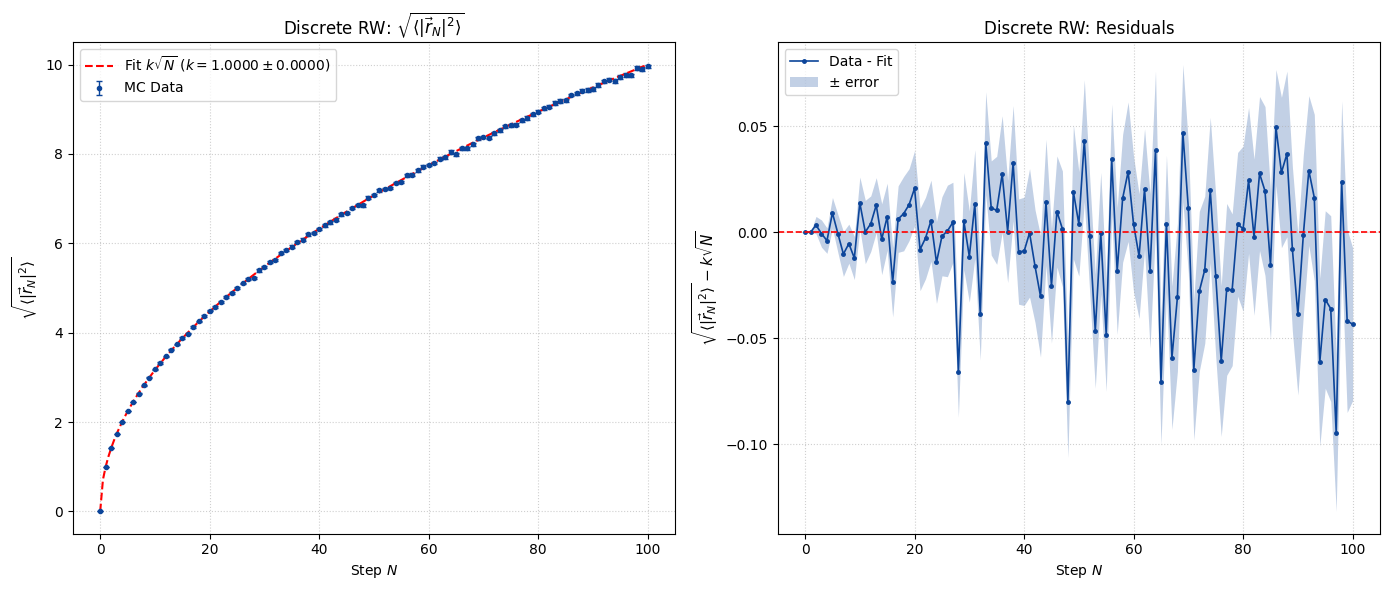

In [8]:
plot_rw(file_discrete, 'Discrete RW', "#0c459a")

From the graphs we can see that the discrete random walk agrees well with the fit: most of the residuals are compatible with zero within $2\sigma$, which confirms the diffusive behaviour of the random walk.

### Continuous RW
For the continuous RW, each step has unit length and its direction is uniformly distributed on the unit sphere. To sample it, the azimuthal angle $\phi$ is drawn uniformly in $[0, 2\pi)$ and $\cos\theta$ uniformly in $[-1, 1]$. Drawing $\theta$ itself uniformly would concentrate the directions near the poles. The code below generates one walk of $i$ steps starting from the origin and accumulates its squared distance:
<small>
```cpp
vector<double> x(3, 0.0);                          // position, starting from the origin

for (int k = 0; k < i; k++){                       
    double phi      = rnd.Rannyu(0, 2*M_PI);      
    double costheta = rnd.Rannyu(-1, 1);           
    double sintheta = sqrt(1.0 - costheta*costheta);
    x[0] += sintheta * cos(phi);
    x[1] += sintheta * sin(phi);
    x[2] += costheta;
}
square_distance += x[0]*x[0] + x[1]*x[1] + x[2]*x[2];
```
</small>

For each number of steps $N$ up to 100, a new set of $M=10^4$ walks was simulated and grouped in $N=100$ blocks of $L=100$ walks each. The results are shown below, together with the fit $k\sqrt{N}$ and its residuals.

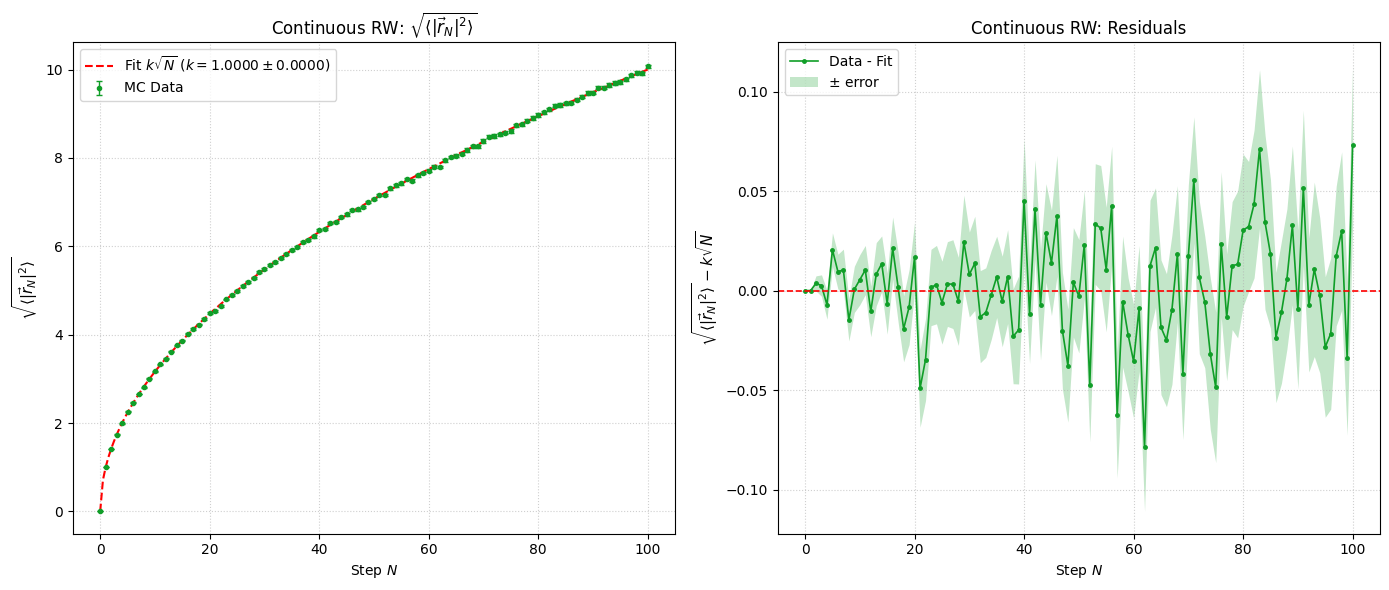

In [9]:
plot_rw(file_continuous, 'Continuous RW', "#109e28")

Again, from the graphs we can see a very good agreement with the fit, confirming the diffusive behaviour of the random walk.